In [95]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [96]:
df=pd.read_csv("credit_risk_dataset.csv")

In [97]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [98]:
df.shape
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB
None


In [99]:
df.isnull().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

In [100]:
df["loan_status"].unique()
df["loan_status"].value_counts()

loan_status
0    25473
1     7108
Name: count, dtype: int64

<Axes: xlabel='loan_status', ylabel='count'>

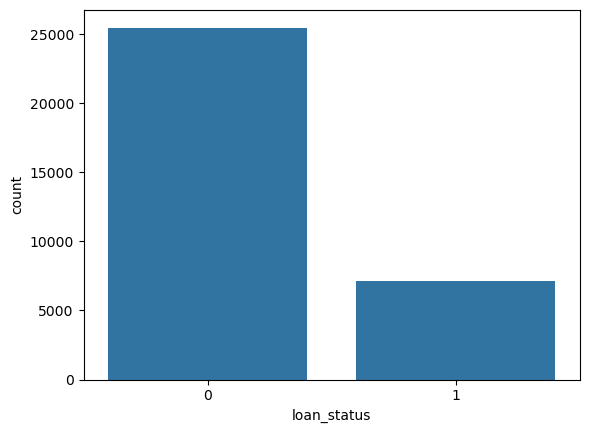

In [101]:
sns.countplot(x='loan_status',data=df)

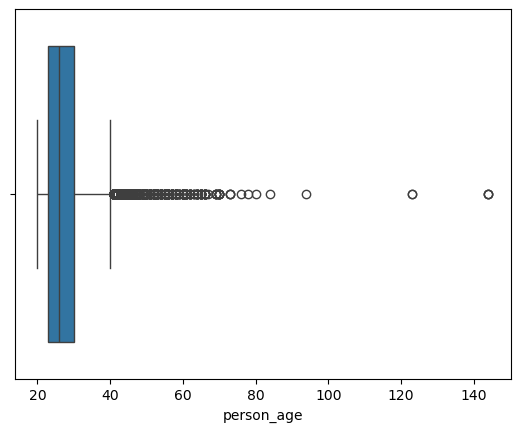

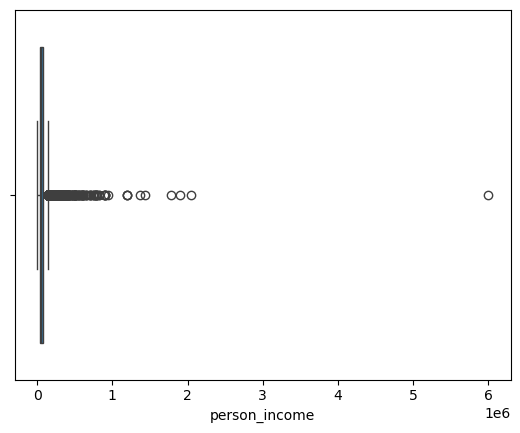

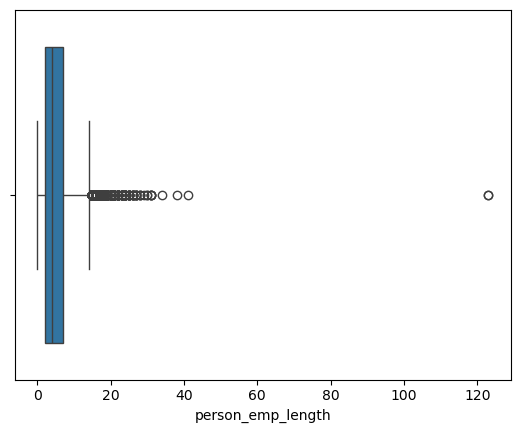

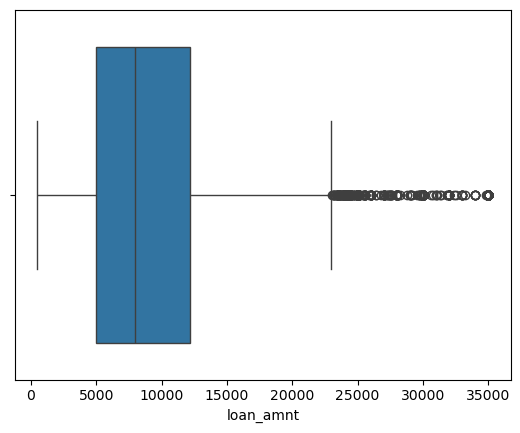

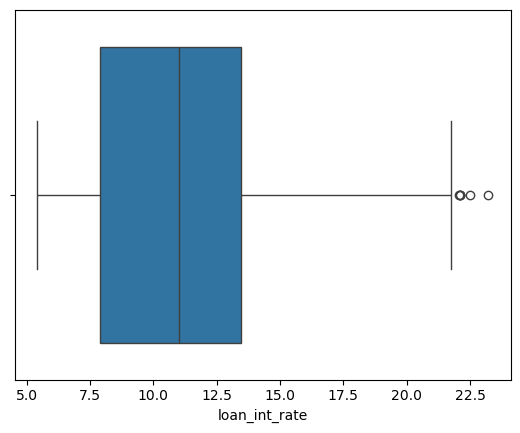

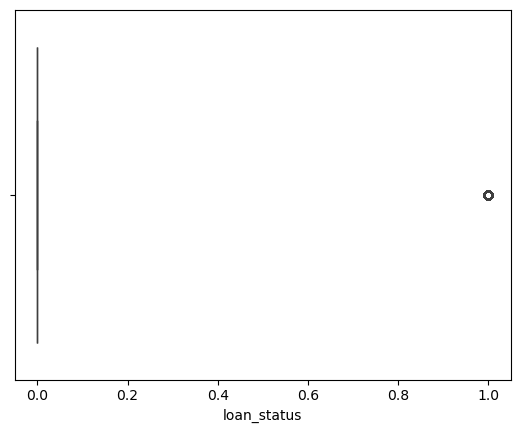

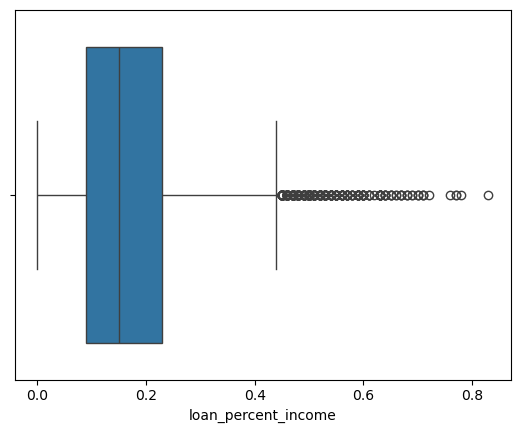

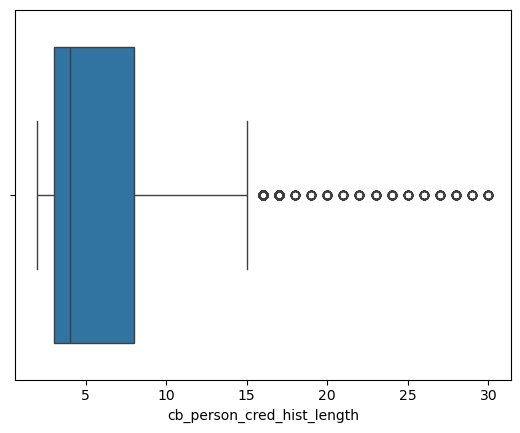

In [102]:
numerical_cols=df.select_dtypes(include=np.number).columns
for i in numerical_cols:
    sns.boxplot(x=df[i])
    plt.show() 



In [103]:
(df["person_age"] >100).sum()

np.int64(5)

In [104]:
(df["person_emp_length"]>60).sum()

np.int64(2)

<Axes: >

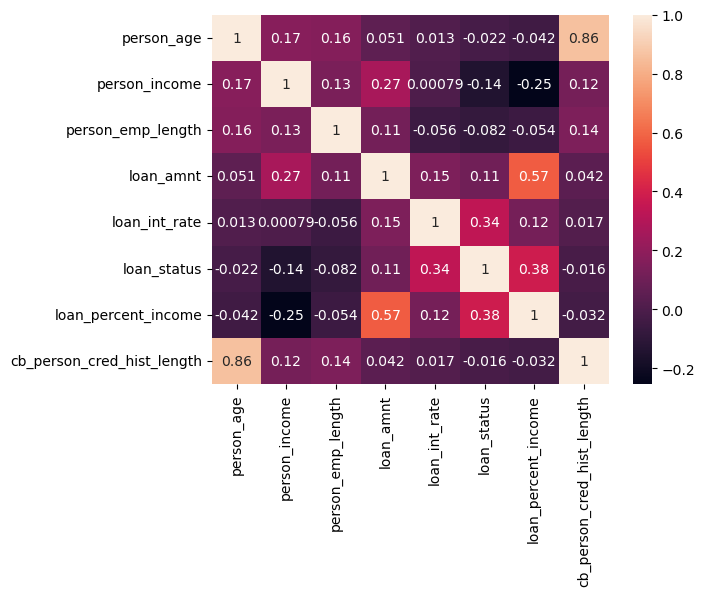

In [105]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

###Data validation and outlier Handilig(means clean, remove, fix, change etc)

In [106]:
df_copy=df.copy()

In [107]:

df_copy = df.copy()

print(f"Original Rows: {df_copy.shape[0]}")

#Remove Duplicate rows
df_copy.drop_duplicates(inplace=True)
print(f"Rows after removing duplicates : {df_copy.shape[0]}")

#Remove ages below 18 or below 100
df_copy = df_copy[df_copy['person_age'] >=18]
df_copy = df_copy[df_copy['person_age'] <=100]

#Remove employment length greater than age or extreme outliers (>60)
df_copy = df_copy[df_copy['person_emp_length'] <= df_copy['person_age']]
df_copy = df_copy[df_copy['person_emp_length'] <= 60]

#Remove the rows with zero or negative income and loan amount.
df_copy = df_copy[df_copy['loan_amnt'] > 0]

#check if the interest rate looks realistic.
print("Loan intreset rate range from (min: 5.42 and max: 23.22)")

Original Rows: 32581
Rows after removing duplicates : 32416
Loan intreset rate range from (min: 5.42 and max: 23.22)


In [108]:
df_copy.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,31522.000000,3.152200e+04,31522.000000,31522.000000,28495.000000,31522.000000,31522.000000,31522.000000
mean,27.742529,6.650168e+04,4.782850,9663.771334,11.045220,0.215944,0.169658,5.816097
std,6.218713,5.275216e+04,4.037343,6334.787700,3.230786,0.411482,0.106296,4.063622
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.943800e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.600000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,8.000000e+04,7.000000,12500.000000,13.480000,0.000000,0.230000,8.000000
max,94.000000,2.039784e+06,41.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [109]:
X=df_copy.drop("loan_status",axis=1)
y=df_copy["loan_status"] #1,0

In [110]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [111]:

numeric_cols = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
                     'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']


categorical_cols = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']


In [112]:
neg,pos=np.bincount(y_train)
scale_pos_weight=neg/pos

In [113]:
#Logistic Regression :Impute +scale Numeric, impute +One-Hot-Encoding

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
preprocessor_lr=ColumnTransformer(
    transformers=[
        #Pipeline- for numerical cols
        ('num',Pipeline([
            ('imputer',SimpleImputer(strategy='median')),
            ('scaler',StandardScaler())
        ]),numeric_cols),
        #Pipeline - for Categorical cols,
        ('cat',Pipeline([
            ('imputer',SimpleImputer(strategy="constant",fill_value="Missing")),
            ('onehot',OneHotEncoder(handle_unknown='ignore'))
        ]),categorical_cols)
    ] 
)

In [114]:
#No scaling in XGBOOST(it does by itself), impute +one -hot encoding
#No scaling needed for XGBoost, Random Forest, or other tree-based models.
preprocessor_xg=ColumnTransformer(
    transformers=[
        #Pipeline- for numerical cols
        ('num',Pipeline([
            ('imputer',SimpleImputer(strategy='median'))
        ]),numeric_cols),
        #Pipeline - for Categorical cols,
        ('cat',Pipeline([
            ('imputer',SimpleImputer(strategy="constant",fill_value="Missing")),
            ('onehot',OneHotEncoder(handle_unknown='ignore'))
        ]),categorical_cols)
    ] 
)

Evaluation Helper Function
  -We build one common function to check any models performance
  

In [115]:
# we have to evaluate logistic model and XGboost model on the basis of their metrics

from sklearn.metrics import accuracy_score,classification_report, precision_score,recall_score,f1_score,confusion_matrix,precision_recall_curve
def evaluate_model(model_name,model,X_test,y_test,threshold=None):
    y_pred_prob =model.predict_proba(X_test)[:,1]

    if threshold:
        y_pred=(y_pred_prob> threshold).astype(int)
    else:
        y_pred=model.predict(X_test)
    
    
    #Metrics
    accuracy=accuracy_score(y_test,y_pred) #Overall model performance
    precision=precision_score(y_test, y_pred) #Of the ones I picked how many were actually right 
    recall=recall_score(y_test,y_pred) #There were actually 20 emails are in the inbox, Found only 8 of them(and missed 12) 8/20=40,,, real defenations=out of everything that eas really there, how much did you manage to find?
    f1=f1_score(y_test, y_pred) #harmonic mean of precision and recall 



#Confusion matrics
    cm =confusion_matrix(y_test,y_pred)
    class_report=classification_report(y_test, y_pred)
    
    

    
    print(f"Accuracy:{accuracy:.2f}")
    print(f"Precision:{precision:.2f}")
    print(f"recall:{recall:.2f}")
    print(f"F1:{f1:.2f}")
    print(f"{model_name} Classification Report:")
    print(class_report)
    


    #plotting confusion Matrix
    sns.heatmap(cm, annot=True,fmt="d")
    plt.title(f"{model_name} Confusion Matrix")
    plt.ylabel("Actual Values")
    plt.xlabel("Predicted Values")
    plt.show()

    #Plotting ROC-AUC curve

    precision, recall, threshold=precision_recall_curve(y_test, y_pred_prob)
    plt.plot(recall,precision )
    plt.xlabel("Recall")
    plt.ylabel("Precisiom")
    plt.title(f"{model_name} precision-Recall Curve")
    plt.show()

In [116]:
from sklearn.model_selection import StratifiedKFold, cross_validate
#Cross validation

cv = StratifiedKFold(n_splits=5, shuffle=True,random_state=42)

scoring = {
    'roc_auc': 'roc_auc',
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1'
}


In [117]:
#Logistic Regression
from sklearn.linear_model import LogisticRegression

lr_cv_pipeline=Pipeline([
    ('preprocessor', preprocessor_lr),
    ("classifier", LogisticRegression(max_iter=1000,class_weight="balanced",random_state=42))# class_weighted focus on minor class . means it equally focus on where value is less. to make it good training
    
])

In [118]:
lr_cv_pipeline

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [119]:
##For Xgboost Model 
from xgboost import XGBClassifier

xgb_cv_pipeline=Pipeline([
    ('preprocessor',preprocessor_xg),
    ('classifier',XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.1,
        scale_pos_weight=scale_pos_weight,#scale_pos_weight tells XGBoost to give more importance to the minority class during training.
        random_state=42


    ))
])



In [120]:
for cv_name, pipe in [("Logistic Regression",lr_cv_pipeline),
                      ("XGBoost", xgb_cv_pipeline)]:
    cv_results=cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    print(cv_name)
    print(f"ROC-AUC:{cv_results['test_roc_auc'].mean()}")
    print(f"Accuracy:{cv_results['test_accuracy'].mean()}")
    print(f"Precision:{cv_results['test_precision'].mean()}")
    print(f"Recall:{cv_results['test_recall'].mean()}")
    print(f"F1:{cv_results['test_f1'].mean()}")

Logistic Regression
ROC-AUC:0.8705112830525306
Accuracy:0.8115949542892269
Precision:0.5448226008889892
Recall:0.7781450872359963
F1:0.6408013995933108
XGBoost
ROC-AUC:0.9470945968526715
Accuracy:0.917952083139717
Precision:0.8190795992296656
Recall:0.7963269054178144
F1:0.8073360762846882


In [121]:
cv_results

{'fit_time': array([2.37422872, 2.41366196, 2.39830685, 2.4089582 , 2.3729589 ]),
 'score_time': array([0.29223752, 0.27941704, 0.29150558, 0.29313684, 0.30915666]),
 'test_roc_auc': array([0.95037143, 0.93802547, 0.94787183, 0.94916053, 0.95004373]),
 'test_accuracy': array([0.92089611, 0.91732752, 0.91631965, 0.91929407, 0.91592306]),
 'test_precision': array([0.82485876, 0.836     , 0.81314554, 0.82048872, 0.80090498]),
 'test_recall': array([0.80440771, 0.76767677, 0.79522498, 0.80165289, 0.81267218]),
 'test_f1': array([0.81450488, 0.80038296, 0.80408542, 0.81096145, 0.80674567])}

Baseline Model -Logistic Regression


In [122]:
baseline_model=Pipeline([
    ('preprocessor',preprocessor_lr),
    ('classifier',LogisticRegression(class_weight="balanced"))
    
])
baseline_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [123]:
xg_model=Pipeline([
    ('preprocessor',preprocessor_xg),
    ('classifier',XGBClassifier( scale_pos_weight=scale_pos_weight,random_state=42,learning_rate=0.1))
])
xg_model.fit(X_train, y_train)


,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


Accuracy:0.82
Precision:0.56
recall:0.79
F1:0.65
Baseline Logistic Model Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305



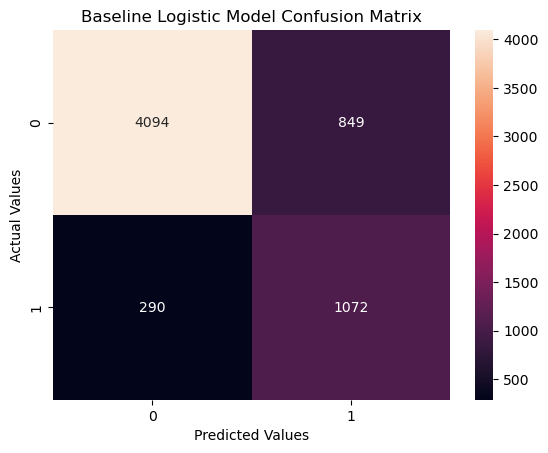

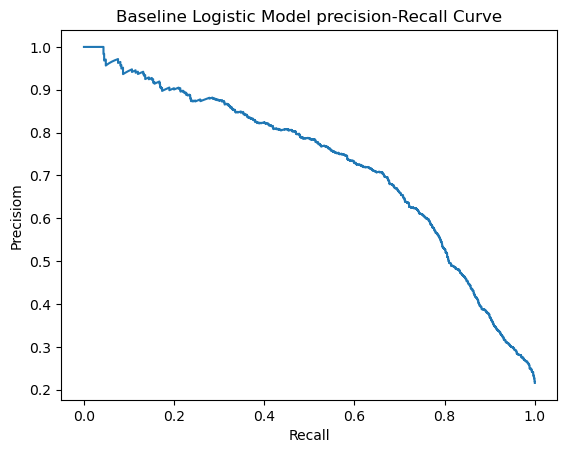

In [124]:
evaluate_model("Baseline Logistic Model",baseline_model,X_test,y_test)

Accuracy:0.92
Precision:0.82
recall:0.79
F1:0.81
Baseline Xgboost Model Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.95      0.95      4943
           1       0.82      0.79      0.81      1362

    accuracy                           0.92      6305
   macro avg       0.88      0.87      0.88      6305
weighted avg       0.92      0.92      0.92      6305



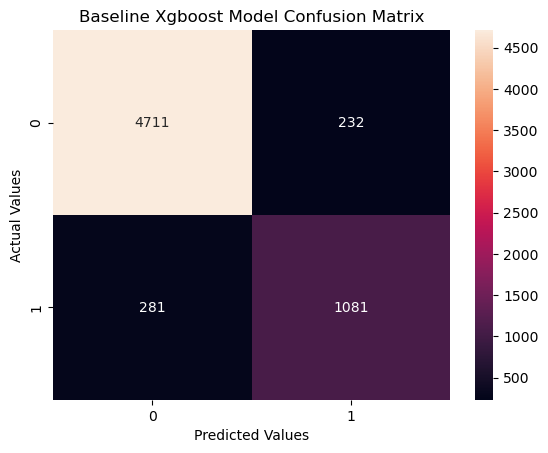

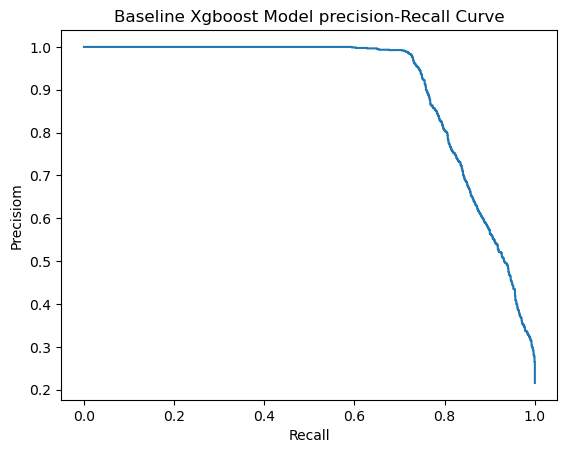

In [125]:
evaluate_model("Baseline Xgboost Model",xg_model,X_test,y_test)

In [126]:
from scipy.stats import uniform, randint

In [127]:

from sklearn.model_selection import RandomizedSearchCV

param_grid={
    "classifier__n_estimators":randint(150,600),
    "classifier__max_depth":randint(3,9),
    "classifier__learning_rate":uniform(0.01,0.5),
    "classifier__subsample":uniform(0.6,0.4),#rows sampling
    "classifier__colsample_bytree":uniform(0.6,0.4),#column sampling
    "classifier__min_child_weight":randint(1,10),
    "classifier__gamma":uniform(0 , 5)
}
#lower gamma =more splits ->complex tree -> higher overfitting risk
#higher gamma =less splits ->simpler tree -> low overfitting 

In [128]:
random_search=RandomizedSearchCV(
    xg_model,
    param_grid,
    n_iter=150,
    cv=cv,
    scoring="average_precision",
    n_jobs=-1,
    verbose=1,
    
    
    
)

random_search.fit(X_train,y_train)


Fitting 5 folds for each of 150 candidates, totalling 750 fits


,estimator,"Pipeline(step...=None, ...))])"
,param_distributions,"{'classifier__colsample_bytree': <scipy.stats....0017587586580>, 'classifier__gamma': <scipy.stats....0017587584F30>, 'classifier__learning_rate': <scipy.stats....0017587FCCE90>, 'classifier__max_depth': <scipy.stats....0017587FCC050>, ...}"
,n_iter,150
,scoring,'average_precision'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,random_state,None
,error_score,nan


In [129]:
random_search.best_params_

{'classifier__colsample_bytree': np.float64(0.8470858844328564),
 'classifier__gamma': np.float64(0.10569221980440746),
 'classifier__learning_rate': np.float64(0.10944286271209484),
 'classifier__max_depth': 7,
 'classifier__min_child_weight': 7,
 'classifier__n_estimators': 379,
 'classifier__subsample': np.float64(0.9713115523027046)}

In [130]:
print(f"score after Tuning{random_search.best_score_:.2f}")

score after Tuning0.90


Accuracy:0.82
Precision:0.56
recall:0.79
F1:0.65
Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305



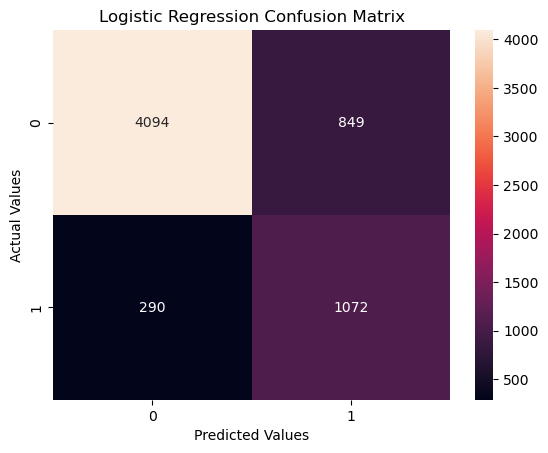

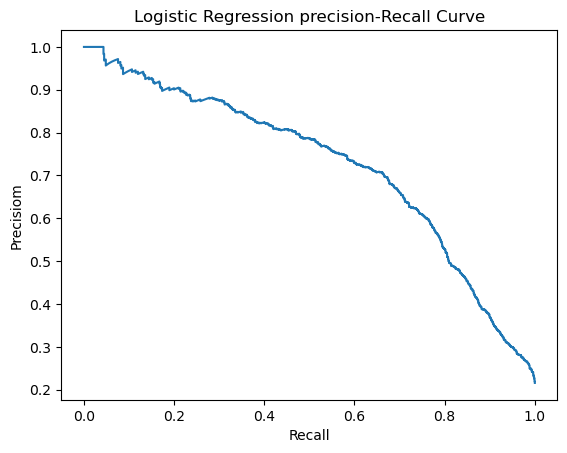

In [131]:
evaluate_model("Logistic Regression",baseline_model,X_test,y_test)

Accuracy:0.93
Precision:0.86
recall:0.80
F1:0.83
XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.96      0.96      4943
           1       0.86      0.80      0.83      1362

    accuracy                           0.93      6305
   macro avg       0.90      0.88      0.89      6305
weighted avg       0.93      0.93      0.93      6305



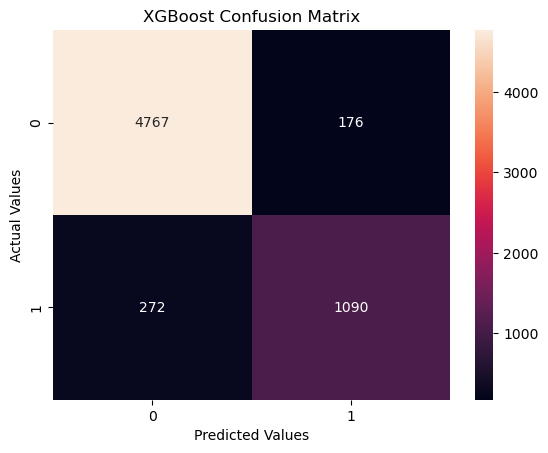

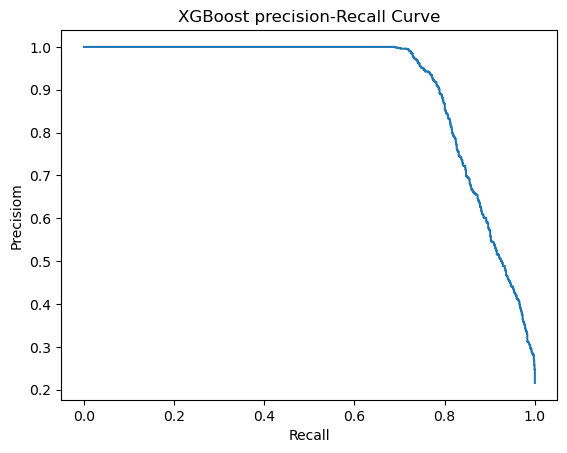

In [132]:
#passing the XGBoost model after performing Hyperparameter Tuning

evaluate_model("XGBoost", random_search,X_test,y_test)

In [133]:
#Random forest
#Adaboost

Random FOREST

Optimizing the classification Threshold
-the model give probability , not direct yes or no.
-we decide a cut -off point to turn it into a decision
-we check diffrent cut-off points and pick the best one

C:\Users\nowsh\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\nowsh\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\nowsh\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\nowsh\anaconda3\Lib\site-pa

Accuracy:0.78
Precision:0.00
recall:0.00
F1:0.00
XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.78      1.00      0.88      4943
           1       0.00      0.00      0.00      1362

    accuracy                           0.78      6305
   macro avg       0.39      0.50      0.44      6305
weighted avg       0.61      0.78      0.69      6305



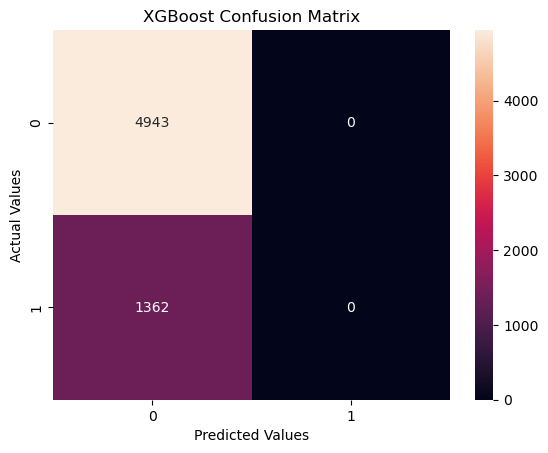

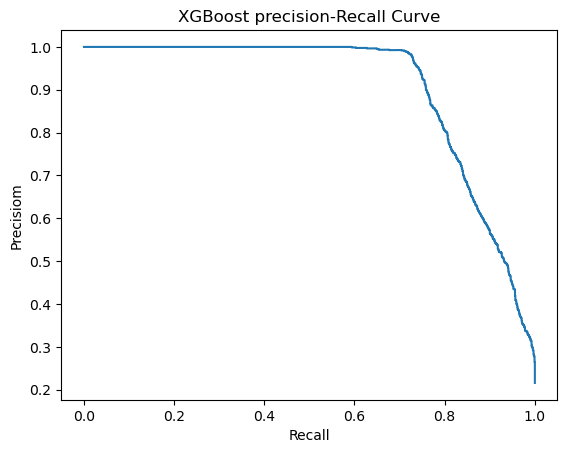

In [134]:
#Get the prob of class 1 from XGBOOST

prob=xg_model.predict_proba(X_test)[:,1]
prob

#for each threshold calculate Precision and Recall
precision, recall, thresholds=precision_recall_curve(y_test, prob)

#calculate F1 score for each threshold
f1 =2 * (precision-recall) / (precision + recall + 1e-9)
f1
#get the threshold that produces the highest f1-score
best= np.argmax(f1[:-1])

best_threshold=thresholds[best]
#Evaluate the XGBOOST model using that threshold

evaluate_model("XGBoost",xg_model, X_test,y_test,best_threshold)



In [135]:
"""
Methods by which we can fix the poorly calibrated model.
1. Platt scaling / Sigmoid -> Adjust the probabilities using the sigmoid curve.
2. Isotonic Regression -> Learn a flexible mapping from old prob. -better probability
3. Temperature Scaling -> Adjust the confidence of neural-netword prediction 

"""

'\nMethods by which we can fix the poorly calibrated model.\n1. Platt scaling / Sigmoid -> Adjust the probabilities using the sigmoid curve.\n2. Isotonic Regression -> Learn a flexible mapping from old prob. -better probability\n3. Temperature Scaling -> Adjust the confidence of neural-netword prediction \n\n'

In [136]:
#1. Calibrated xgBoost model

from sklearn.calibration import CalibratedClassifierCV,calibration_curve
best_model=random_search.best_estimator_
calibrated_model=CalibratedClassifierCV(
    best_model,
    method="sigmoid",
    cv=5
)

calibrated_model.fit(X_train, y_train)



,estimator,"Pipeline(step...=None, ...))])"
,method,'sigmoid'
,cv,5
,n_jobs,None
,ensemble,'auto'
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False


In [137]:
#2.get probabilities


uncalibrated =xg_model.predict_proba(X_test)[:,1]


calibrated=calibrated_model.predict_proba(X_test)[:,1]



In [138]:


#3. create calibration curves
actual_uncal, predicted_uncal=calibration_curve(y_test, uncalibrated, n_bins=10)


In [139]:
actual_cal, predicted_cal=calibration_curve(y_test,calibrated,n_bins=10)


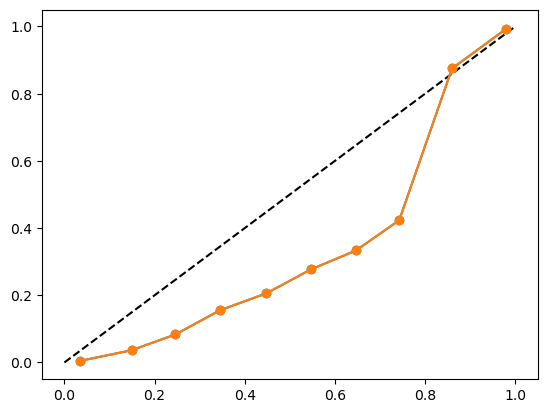

In [140]:
#plot(to see how my model is looking) 
plt.plot([0,1],[0,1], 'k--',label="perfact")
plt.plot(
    predicted_uncal,
    actual_uncal,
    "o-",
    label="Uncalibrated"
    
)


plt.plot(
    predicted_uncal,
    actual_uncal,
    "o-",
    label="Calibrated"
    
)


In [141]:
#!pip install shap

In [142]:
import shap
#2Get the trained Xgboost classifier model of the pipeline

xgb_classifier =xg_model.named_steps['classifier']
xgb_classifier

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,None


In [143]:
#3. Transform X_test using the same preprocessing used for training 
X_test_transformed=xg_model.named_steps['preprocessor'].transform(X_test)


In [144]:
#4. Get feature names after one-hot encoding, so plots are readable


feature_names=xg_model.named_steps['preprocessor'].get_feature_names_out()

In [145]:
#5. Convert to a dataframe for cleaner shap plots

X_test_df=pd.DataFrame(X_test_transformed, columns=feature_names)
X_test_df


,num__person_age,num__person_income,num__person_emp_length,num__loan_amnt,num__loan_int_rate,num__loan_percent_income,num__cb_person_cred_hist_length,cat__person_home_ownership_MORTGAGE,cat__person_home_ownership_OTHER,cat__person_home_ownership_OWN,...,cat__loan_intent_VENTURE,cat__loan_grade_A,cat__loan_grade_B,cat__loan_grade_C,cat__loan_grade_D,cat__loan_grade_E,cat__loan_grade_F,cat__loan_grade_G,cat__cb_person_default_on_file_N,cat__cb_person_default_on_file_Y
0,24.0,30000.0,1.0,15000.0,15.68,0.50,3.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,23.0,60000.0,6.0,25600.0,10.99,0.43,4.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2,29.0,18000.0,2.0,3600.0,15.27,0.20,6.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3,32.0,130000.0,7.0,13000.0,12.69,0.10,8.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,23.0,45288.0,7.0,20500.0,9.25,0.45,2.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6300,21.0,75000.0,5.0,20000.0,13.11,0.27,2.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
6301,29.0,265000.0,2.0,25000.0,11.26,0.09,10.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
6302,25.0,48996.0,8.0,5000.0,9.88,0.10,2.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
6303,27.0,115000.0,11.0,8000.0,7.51,0.07,7.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [146]:
#6. Create Shap explaner built for tree-based model

explainer=shap.TreeExplainer(xgb_classifier)

In [147]:
explainer

In [148]:
#7 Calculate Shap  values for every row in the test set

shap_values= explainer.shap_values(X_test_df)
shap_values

array([[-1.7525564e-01, -1.0555401e-01,  1.2984274e-01, ...,
        -7.3516299e-03, -3.8879909e-02,  0.0000000e+00],
       [ 4.7165085e-02, -8.7262326e-01, -9.4737314e-02, ...,
        -9.2151780e-03, -7.5508673e-03,  0.0000000e+00],
       [ 7.8027323e-02,  3.5025654e+00,  1.2711690e-01, ...,
        -7.3584518e-03,  7.7456667e-04,  0.0000000e+00],
       ...,
       [-8.6244913e-03,  5.8208084e-01,  7.2391242e-02, ...,
        -9.2837382e-03, -1.1459960e-02,  0.0000000e+00],
       [ 2.0838849e-02, -1.0313793e+00,  4.3692421e-02, ...,
        -9.2305308e-03, -1.1398584e-02,  0.0000000e+00],
       [-1.3665082e-01, -5.0866711e-01,  2.6854105e-02, ...,
        -8.8342456e-03, -1.0388625e-02,  0.0000000e+00]],
      shape=(6305, 26), dtype=float32)

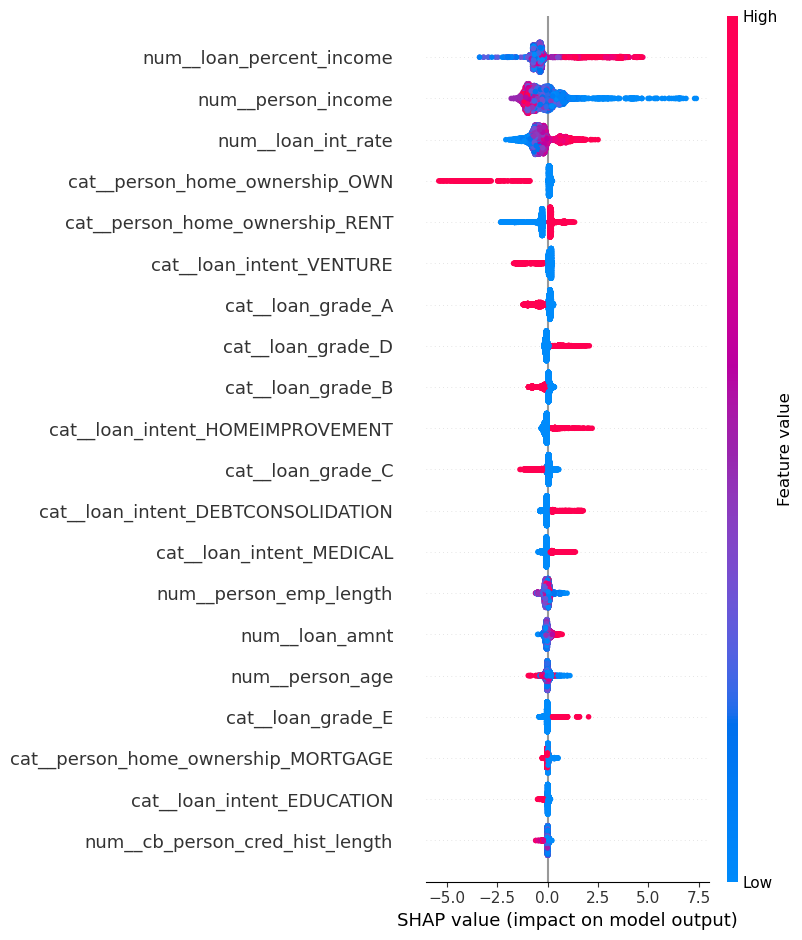

In [149]:
shap.summary_plot(shap_values, X_test_df)

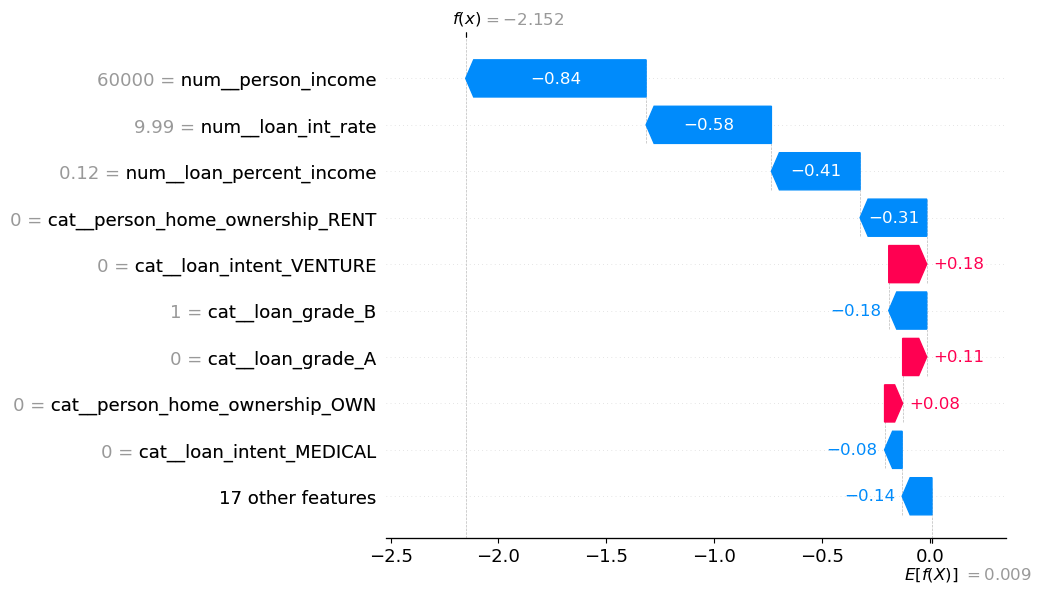

In [150]:
#Pick one row to explain, e.g the 5th applicant in the test set.

row_index=5

#2. Draw a waterfall plot showing how each feature pushed the prediction up or down

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[row_index],
        base_values=explainer.expected_value,
        data=X_test_df.iloc[row_index],
        feature_names=feature_names
        
    )
)

In [151]:
#Get predictions from the best performing XGBOSST model on the test set

y_pred=random_search.predict(X_test)

In [152]:
#Create a dataframe to easily compare the actual and predicted values
result_df=X_test.copy()
result_df['actual']= y_test
result_df['predicted']=y_pred

In [153]:
result_df

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,actual,predicted
14455,24,30000,OWN,1.0,MEDICAL,E,15000,15.68,0.50,N,3,1,1
8701,23,60000,MORTGAGE,6.0,EDUCATION,C,25600,NaN,0.43,N,4,0,0
19804,29,18000,RENT,2.0,EDUCATION,C,3600,15.27,0.20,N,6,1,1
27252,32,130000,MORTGAGE,7.0,MEDICAL,B,13000,12.69,0.10,N,8,0,0
5610,23,45288,MORTGAGE,7.0,DEBTCONSOLIDATION,B,20500,9.25,0.45,N,2,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
11661,21,75000,MORTGAGE,5.0,PERSONAL,C,20000,13.11,0.27,Y,2,0,0
27837,29,265000,MORTGAGE,2.0,PERSONAL,B,25000,11.26,0.09,N,10,0,0
17192,25,48996,MORTGAGE,8.0,MEDICAL,B,5000,9.88,0.10,N,2,1,1
26858,27,115000,MORTGAGE,11.0,MEDICAL,A,8000,7.51,0.07,N,7,0,0


In [154]:
#Identify false Positive:Model Predicted 1, but the actual was 0

false_positive=result_df[(result_df['actual']==0) & (result_df['predicted']==1)]


#Identify False Negative: Model predicted 0, but the actual was 1
false_negative=result_df[(result_df['actual']==1) & (result_df['predicted']==0)]




In [155]:
print(f"False Positive:{len(false_positive)}")
print(f"False Positive:{len(false_negative)}")

False Positive:176
False Positive:272


In [156]:
#save

import joblib
joblib.dump(calibrated_model,"credit_risk_model.pkl")

['credit_risk_model.pkl']

In [159]:
joblib.dump(best_threshold,"best_threshold.pkl")

['best_threshold.pkl']

In [158]:
from sklearn.metrics import precision_recall_curve

import numpy as np

#get probabilities from CALIBRATED model, not the old xg_model
    
calibrated_proba=calibrated_model.predict_proba(X_test)[:,1]

#2 Re-run the same threshold search , now on the correct probability scale

precisions,recalls, thresholds=precision_recall_curve(y_test,calibrated_proba)
f1_scores=2* (precisions * recalls) / (precisions +recalls + 1e-9)

best_threshold=thresholds[np.argmax(f1_scores[:-1])]

print("New threshold",best_threshold)

New threshold 0.6170454776797389
